In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.interpolate import RectBivariateSpline
from matplotlib import rcParams
rcParams['figure.figsize'] = (6,6)

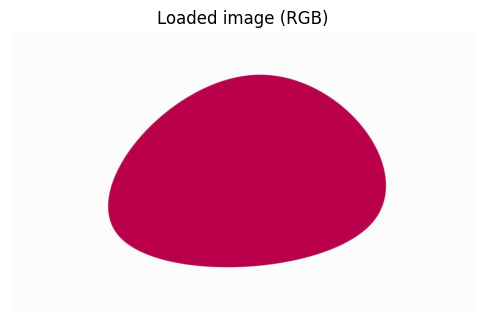

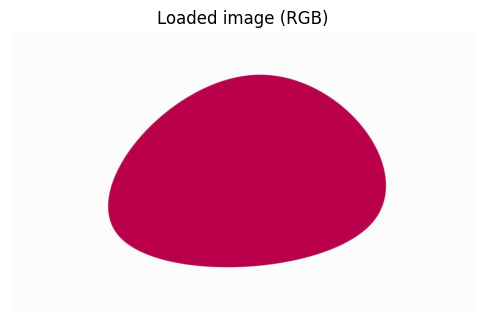

In [2]:
img_bgr = cv2.imread('img.jpg', cv2.IMREAD_COLOR)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_gray_smooth = ndimage.gaussian_filter(img_gray, sigma=3)
fig, ax = plt.subplots()
ax.imshow(img_rgb)
ax.set_title('Loaded image (RGB)')
ax.axis('off')
fig

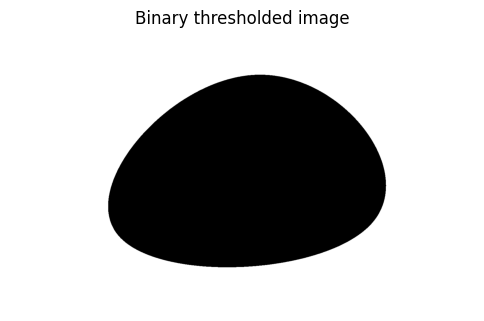

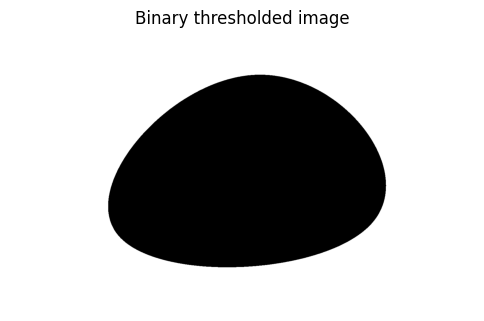

In [3]:
_, thresh = cv2.threshold(img_gray_smooth.astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
fig, ax = plt.subplots()
ax.imshow(thresh, cmap='gray')
ax.set_title('Binary thresholded image')
ax.axis('off')
fig

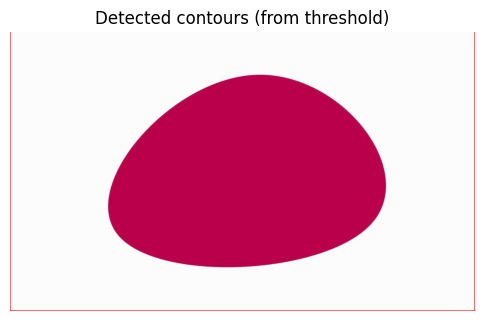

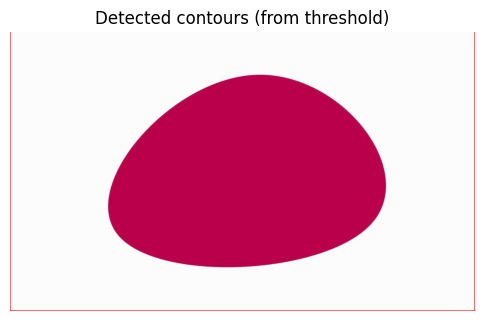

In [4]:
cnts_info = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = cnts_info[0] if len(cnts_info) == 2 else cnts_info[1]
img_cont = img_rgb.copy()
cv2.drawContours(img_cont, contours, -1, (255,0,0), 2)
fig, ax = plt.subplots()
ax.imshow(img_cont)
ax.set_title('Detected contours (from threshold)')
ax.axis('off')
fig

In [5]:
def internal_energy_matrix(N, alpha, beta):
    D2 = np.zeros((N, N))
    D4 = np.zeros((N, N))
    for i in range(N):
        D2[i, i] = -2
        D2[i, (i-1) % N] = 1
        D2[i, (i+1) % N] = 1
        D4[i, i] = 6
        D4[i, (i-1) % N] = -4
        D4[i, (i+1) % N] = -4
        D4[i, (i-2) % N] = 1
        D4[i, (i+2) % N] = 1
    A = alpha * D2 + beta * D4
    return A
Ntest = 12
A_test = internal_energy_matrix(Ntest, 0.1, 0.1)
A_test

array([[ 0.4, -0.3,  0.1,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0.1,
        -0.3],
       [-0.3,  0.4, -0.3,  0.1,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
         0.1],
       [ 0.1, -0.3,  0.4, -0.3,  0.1,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
         0. ],
       [ 0. ,  0.1, -0.3,  0.4, -0.3,  0.1,  0. ,  0. ,  0. ,  0. ,  0. ,
         0. ],
       [ 0. ,  0. ,  0.1, -0.3,  0.4, -0.3,  0.1,  0. ,  0. ,  0. ,  0. ,
         0. ],
       [ 0. ,  0. ,  0. ,  0.1, -0.3,  0.4, -0.3,  0.1,  0. ,  0. ,  0. ,
         0. ],
       [ 0. ,  0. ,  0. ,  0. ,  0.1, -0.3,  0.4, -0.3,  0.1,  0. ,  0. ,
         0. ],
       [ 0. ,  0. ,  0. ,  0. ,  0. ,  0.1, -0.3,  0.4, -0.3,  0.1,  0. ,
         0. ],
       [ 0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0.1, -0.3,  0.4, -0.3,  0.1,
         0. ],
       [ 0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0.1, -0.3,  0.4, -0.3,
         0.1],
       [ 0.1,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0.1, -0.3,  0.4,
        -0.3],
       [-0.3,  0.1,  

**Roles of alpha (α) and beta (β)**

- **α (Elasticity)**: Controls tension along the snake, acting like a first-derivative penalty that resists stretching. Higher α makes the snake behave more like a tight rubber band, favoring shorter contours and smoother, tighter fits to local minima.
- **β (Bending / Stiffness)**: Controls the bending resistance (second-derivative penalty). Higher β resists curvature, producing smoother contours that avoid sharp corners.

**Effect of extreme values**
- If α is too large: snake becomes overly tight and may shrink, failing to settle on object boundaries (over-smoothing).
- If α is too small: snake can become too elastic and noisy, allowing irregular shapes and possibly breaking apart around concavities.
- If β is too large: snake strongly resists bending and will remain overly smooth, failing to capture corners or narrow features.
- If β is too small: snake can form sharp kinks and overfit to noise in the external energy.

When α or β are poorly chosen the internal forces dominate or under-constrain the contour, so balancing them with the external image forces is key.

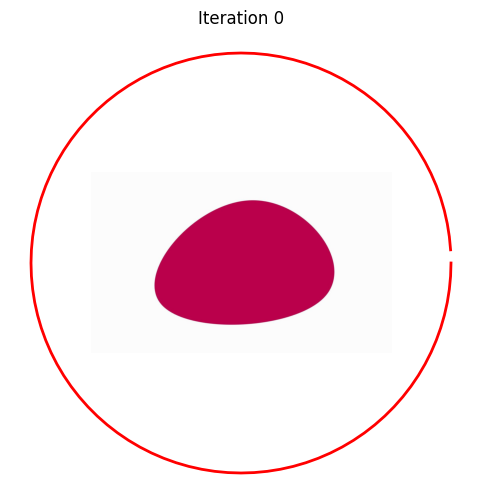

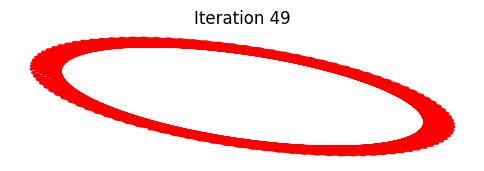

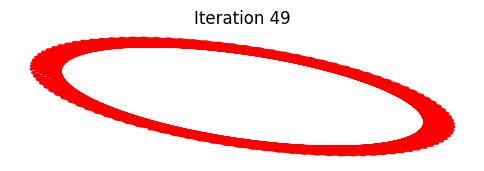

In [ ]:
def active_contour(img_gray, init, alpha=0.1, beta=0.1, gamma=0.1, max_iter=200, display_step=25):
    img_s = ndimage.gaussian_filter(img_gray.astype(float), 3)
    gy, gx = np.gradient(img_s)
    height, width = img_gray.shape
    x = init[:, 0].astype(float)
    y = init[:, 1].astype(float)
    N = len(x)
    A = internal_energy_matrix(N, alpha, beta)
    inv = np.linalg.inv(np.eye(N) - gamma * A)
    spline_gx = RectBivariateSpline(np.arange(height), np.arange(width), gx)
    spline_gy = RectBivariateSpline(np.arange(height), np.arange(width), gy)
    figs = []
    for i in range(max_iter):
        fx = spline_gx.ev(y, x)
        fy = spline_gy.ev(y, x)
        x = inv.dot(x + gamma * fx)
        y = inv.dot(y + gamma * fy)
        if (i % display_step) == 0 or i == max_iter - 1:
            fig, ax = plt.subplots()
            ax.imshow(img_rgb)
            ax.plot(x, y, '-r', lw=2)
            ax.set_title(f'Iteration {i}')
            ax.axis('off')
            plt.show()
            figs.append(fig)
    return np.column_stack([x, y]), figs
largest = max(contours, key=lambda c: cv2.contourArea(c))
cnt = largest.reshape(-1, 2)
cx = cnt[:, 0].mean()
cy = cnt[:, 1].mean()
r = np.sqrt(((cnt[:, 0] - cx) ** 2 + (cnt[:, 1] - cy) ** 2)).max() * 1.2
t = np.linspace(0, 2 * np.pi, 100, endpoint=False)
init_snake = np.column_stack([cx + r * np.cos(t), cy + r * np.sin(t)])
snake_points, figs = active_contour(img_gray_smooth, init_snake, alpha=0.5, beta=10, gamma=0.1, max_iter=50, display_step=50)
figs[-1]